<a href="https://colab.research.google.com/github/aer00file/Eden_INFO4670_Fall2026/blob/main/MEJ0167_Week5_INFO4670_Assignment2_Framework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# INFO 4670 / 4760 — Assignment 2 (Framework)
### Cleaning & Integrating the Northgate Data

Fill in each **# TODO** cell with your code, then run the **✅ Check** cell under it to see if it passes. Work top to bottom. When you're done, run the whole notebook once (Runtime → Run all), make sure it runs cleanly, and submit your **GitHub link**.

- Do every fix on a **copy** — never overwrite the raw files.
- The Week 5 Guided notebook shows every technique you need.
- You're graded on correct operations **and** justified decisions (see the rubric).

## Setup — load the three files (given)

In [202]:
import pandas as pd, numpy as np, os
try:
    students = pd.read_csv("student_records.csv")
except FileNotFoundError:
    from google.colab import files
    print("Upload student_records.csv, course_enrollments.csv, weekly_activity.csv")
    files.upload()
    students = pd.read_csv("student_records.csv")
enroll   = pd.read_csv("course_enrollments.csv")
activity = pd.read_csv("weekly_activity.csv")
# Golden rule: work on copies, never overwrite the raw files.
print("students", students.shape, "| enroll", enroll.shape, "| activity", activity.shape)

students (2027, 12) | enroll (8088, 4) | activity (32000, 4)


## Part A · Clean student_records

### A1 · Missing values
Find how many values are missing in `study_hours_reported` and store the count as **`n_missing_study`**. Then, in the markdown cell after your code, say in 1–2 sentences which of Han's methods you would use to handle it and why.
*Hint:* `.isna().sum()`

In [20]:
# TODO: set n_missing_study to the number of blank study_hours_reported values
n_missing_study = students["study_hours_reported"].isna().sum()
print(f"\nstudy_hours_reported: {n_missing_study} blank of {len(students)} "
      f"({n_missing_study/len(students)*100:.1f}%) -> {students['study_hours_reported'].notna().sum()} present")


study_hours_reported: 255 blank of 2027 (12.6%) -> 1772 present


**Your justification (1–2 sentences):** Method 4 using the median would work best because the data is skewed.

In [21]:
# ✅ Check
try:
    assert n_missing_study == 255
    print("✅ A1 correct — 255 missing (n = 1772 present)")
except Exception:
    print("❌ A1 not yet — set n_missing_study to the count of blank study_hours_reported")

✅ A1 correct — 255 missing (n = 1772 present)


### A2 · Inconsistent categories
Standardize the `housing` column into its three real groups and store the result as a new column **`students["housing_clean"]`**.
*Hint:* `.str.strip().str.lower().map({...})`

In [30]:
# TODO: create students["housing_clean"] with exactly 3 standardized groups
students["housing_clean"] = students["housing"].str.strip().str.lower().map({'off campus':'off-campus', 'off-campus' : 'off-campus', 'on-campus' : 'on-campus', 'with family' : 'with family'})
print(f"\nhousing_clean categories: {students["housing_clean"].unique()}")


housing_clean categories: ['off-campus' 'with family' 'on-campus']


In [31]:
# ✅ Check
try:
    assert students["housing_clean"].nunique() == 3
    print("✅ A2 correct — 3 groups:", {k:int(v) for k,v in students["housing_clean"].value_counts().items()})
except Exception:
    print("❌ A2 not yet — housing_clean should have exactly 3 groups (expect 590 / 945 / 492)")

✅ A2 correct — 3 groups: {'off-campus': 945, 'on-campus': 590, 'with family': 492}


### A3 · Errors vs. extremes
Find the impossible values. Store the sorted unique impossible ages as **`impossible_ages`** and the number of rows with negative work hours as **`n_neg_work`**. (Remember: extreme-but-valid values like a long commute are *kept*.)
*Hint:* boolean masks on `age` and `work_hours_per_week`.

In [119]:
# TODO
impossible_ages_df = students[(students["age"] < 0) | (students["age"] > 120)]
impossible_ages_s = impossible_ages_df['age']
impossible_ages = impossible_ages_s.to_list()
print(f"Impossible ages: \n{impossible_ages}")

n_neg_work = (students["work_hours_per_week"] < 0).sum()
print(f"Neg work hours: {n_neg_work}")

Impossible ages: 
[199, -22, 220]
Neg work hours: 4


In [120]:
()# ✅ Check
try:
    assert 220 in impossible_ages and -22 in impossible_ages and n_neg_work == 4
    print("✅ A3 correct — impossible ages incl. -22/199/220; 4 negative work-hour rows")
except Exception:
    print("❌ A3 not yet — check ages (e.g. -22, 199, 220) and count negative work hours (expect 4)")

✅ A3 correct — impossible ages incl. -22/199/220; 4 negative work-hour rows


### A4 · Duplicates
Remove duplicate **student** records and store the result as **`students_dedup`**. Then, in the markdown cell after your code, explain in one sentence why you must NOT de-duplicate `enroll` or `activity` by ID.
*Hint:* `.drop_duplicates()` — think about exact vs. near-duplicates.

In [163]:
# TODO: build students_dedup (one row per student)
students_dedup = students.drop_duplicates(subset=['student_id'])
print(len(students_dedup))

2000


**Why not de-dupe enroll / activity? (1 sentence):** Multiple students could reasonably have identical values for enrollment and/or activity.

In [110]:
# ✅ Check
try:
    assert len(students_dedup) == 2000 and students_dedup["student_id"].is_unique
    print("✅ A4 correct — 2000 unique students (from 2027 rows)")
except Exception:
    print("❌ A4 not yet — students_dedup should be 2000 rows, one per student")

✅ A4 correct — 2000 unique students (from 2027 rows)


## Part B · Integrate the three files

### B5 · Standardize the key & integrate
Build one **row-per-student** analysis table called **`analysis`**: start from `students_dedup`, add a standardized numeric key, and merge in a per-student summary of `activity` (e.g., total `minutes_active`).
*Hint:* make the key with `.str.replace("NU-","")` → `int`; summarize activity with `groupby(...).sum()`; then `merge`.

In [216]:
# TODO: build the standardized key and the one-row-per-student "analysis" table
students_dedup['standardized_key'] = students_dedup['student_id'].str.replace("NU-","")
students_dedup['standardized_key'] = students_dedup['standardized_key'].astype('int')
#activity['standardized_key'] = activity['student_id'].str.replace("NU-","")
activity = activity.groupby('student_id').sum()
analysis = pd.merge(students_dedup, activity, on='student_id')
print(analysis)

     student_id                   major  age      housing  commute_miles  \
0     NU-101508            Data Science   27   Off-Campus            7.6   
1     NU-102438   Learning Technologies   25  With Family           14.3   
2     NU-102385   Learning Technologies   26  With Family            3.4   
3     NU-100767          Cyber Security   22    On-Campus           23.7   
4     NU-106054  Information Technology   21   Off-Campus            2.3   
...         ...                     ...  ...          ...            ...   
1995  NU-102485      Business Analytics   21   Off-Campus            2.8   
1996  NU-104031           Cybersecurity   31  With Family           23.4   
1997  NU-108652  Information Technology   21  With Family            5.5   
1998  NU-100253      Business Analytics   25   Off-Campus           20.7   
1999  NU-102648           Cybersecurity   25    on-campus            7.2   

      work_hours_per_week  advisor_meetings  credits_attempted  final_gpa  \
0         

In [206]:
# ✅ Check
try:
    assert len(analysis) == 2000 and analysis["student_id"].is_unique
    print("✅ B5 correct — one row per student, 2000 rows")
except Exception:
    print("❌ B5 not yet — analysis should have one row per student (2000)")

✅ B5 correct — one row per student, 2000 rows


### B6 · Verify the join
Report how many `enroll` rows match a student in your standardized key. Store the count as **`matched`**.
*Hint:* `enroll["sid"].isin(set_of_keys).sum()`

In [219]:
# TODO
set_of_keys_S = analysis['standardized_key']
set_of_keys = set_of_keys_S.tolist()
matched = enroll["sid"].isin(set_of_keys).sum()
print(matched)

8041


In [218]:
# ✅ Check
try:
    assert matched == 8041
    print("✅ B6 correct — 8041 of 8088 enrollment rows match (14 orphan IDs)")
except Exception:
    print("❌ B6 not yet — count enrollment rows whose sid is in your student keys (expect 8041)")

✅ B6 correct — 8041 of 8088 enrollment rows match (14 orphan IDs)


## Part C · Transform

### C7 · Parse the dates
Parse `enrollment_date` so no valid date is lost. Store the parsed series as **`dates_parsed`** and check the number of NaT (blanks).
*Hint:* `pd.to_datetime(..., format="mixed", errors="coerce")` — compare NaT before and after.

In [220]:
# TODO
dates_parsed = pd.to_datetime(analysis['enrollment_date'], format="mixed", errors="coerce")

In [221]:
# ✅ Check
try:
    assert dates_parsed.isna().sum() == 0
    print("✅ C7 correct — all dates parsed, 0 lost (a naive parse would lose ~1470)")
except Exception:
    print("❌ C7 not yet — parse every format so no valid date becomes NaT")

✅ C7 correct — all dates parsed, 0 lost (a naive parse would lose ~1470)


### C8 · Normalize & discretize
Add two columns to `analysis`: a **z-scored** numeric column stored as **`analysis["study_z"]`**, and a **GPA band** column stored as **`analysis["gpa_band"]`** (bin `final_gpa` into 4 bands).
*Hint:* z-score = `(x - x.mean()) / x.std()`; bands = `pd.cut(..., bins=[-0.01,1,2,3,4])`.

In [224]:
# TODO: add analysis["study_z"] and analysis["gpa_band"]
analysis['study_z'] = (analysis['study_hours_reported'] - analysis['study_hours_reported'].mean()) / analysis['study_hours_reported'].std()
analysis['gpa_band'] = pd.cut(analysis['final_gpa'], bins=[-0.01,1,2,3,4])

In [225]:
# ✅ Check
try:
    assert analysis["gpa_band"].nunique() == 4 and abs(analysis["study_z"].mean()) < 0.01
    print("✅ C8 correct — z-score (mean ≈ 0) and 4 GPA bands added")
except Exception:
    print("❌ C8 not yet — add a z-scored column and a 4-band gpa_band column")

✅ C8 correct — z-score (mean ≈ 0) and 4 GPA bands added


## Part D · Deliver & reflect

### D9 · Write the clean file
Write your clean `analysis` table to **`northgate_clean.csv`** (do NOT overwrite the raw files).
*Hint:* `.to_csv("northgate_clean.csv", index=False)`

In [226]:
# TODO: write analysis to northgate_clean.csv
analysis.to_csv("northgate_clean.csv", index=False)

In [227]:
# ✅ Check
try:
    assert os.path.exists("northgate_clean.csv")
    print("✅ D9 correct — northgate_clean.csv written (raw files untouched)")
except Exception:
    print("❌ D9 not yet — write analysis to northgate_clean.csv")

✅ D9 correct — northgate_clean.csv written (raw files untouched)


### D10 · Cleaning log
In the markdown cell below, list each decision you made above and a one-line justification for it (missing values, housing, impossible values, duplicates, key, dates). *This is graded — no code needed.*

**Your cleaning log:**
- Housing values were replaced with cleaned version "on-campus", "off-campus","with family" -- all other entries are variations of the above with no difference in value
- Ages not in the range of 0 to 120 are considered impossible. All ages reasonable for a student are within this range
- Hours worked less than 0 are considered impossible. It is impossible to work a negative number of hours (for now)
- Duplicate Student ID values were removed. Student IDs are understood to be unqiue, thus duplicates must be errors
- Standardized key uses a stripped version of the Student ID. All non-numeric information does not identify the student

### D11 · Payoff
Using your clean `analysis` table, report the **mean GPA** and **one relationship** you find interesting, then note in one sentence how cleaning changed the picture versus the raw data.

Cleaned Mean GPA: 2.31


With the cleaned data, we can see that a students expected final GPA has a positive corellation with the number of minutes they spent engaged. 
 In the raw data, this couldn't be seen because the activity information was stored weekly rather than semester-wide.


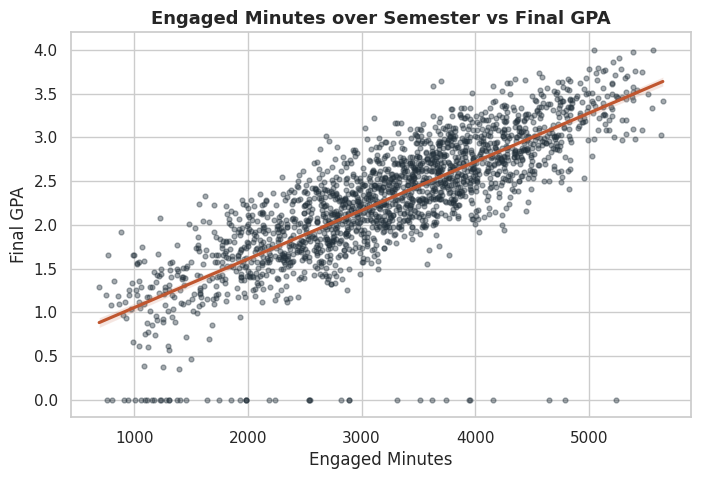

In [243]:
# TODO: compute the mean GPA and explore one relationship on the CLEAN data
import matplotlib.pyplot as plt
import seaborn as sns

# Northgate house style (optional, but keeps your charts consistent)
NAVY = "#22303A"
RUST = "#C0562F"
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"]   = (8, 5)
plt.rcParams["axes.titlesize"]   = 13
plt.rcParams["axes.titleweight"] = "bold"

print(f"Cleaned Mean GPA: {analysis['final_gpa'].mean():.2f}\n\n")
print("With the cleaned data, we can see that a students expected final GPA has a positive corellation with the number of minutes they spent engaged. \n In the raw data, this couldn't be seen because the activity information was stored weekly rather than semester-wide.")

fig, ax = plt.subplots()
sns.regplot(data=analysis, x="minutes_active", y="final_gpa", scatter_kws={"s": 12, "color": NAVY, "alpha": 0.4}, line_kws={"color": RUST},ax=ax)   # which chart? which column(s)?
ax.set_title("Engaged Minutes over Semester vs Final GPA")
ax.set_xlabel("Engaged Minutes")
ax.set_ylabel("Final GPA")
plt.show()

In [ ]:
# ✅ Check
print("(D11 is interpreted by your instructor — make sure your numbers and one-sentence takeaway are shown above.)")